In [1]:
# Collect the data
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: /home/sudipto/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


In [2]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [3]:

DATASET_PATH = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

df = pd.read_csv(DATASET_PATH)

In [4]:

ROOT_DIR = os.path.dirname(os.getcwd())

DATA_DIR = os.path.join(ROOT_DIR, 'data')
DATA_DIR_RAW = os.path.join(DATA_DIR, 'raw')
DATA_DIR_PROCESSED = os.path.join(DATA_DIR, 'processed')

DATASET_NAME_V1 = f"{DATA_DIR_RAW}/churnv1.csv"

# df.to_csv(DATASET_NAME_V1, index=True)



#### Load the dataset

In [5]:
df = pd.read_csv(DATASET_NAME_V1)

df.sample(5)

,Unnamed: 0,index,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3905,3905,3905,5759-RCVCB,Female,0,No,No,3,No,No phone service,...,No,No,Yes,No,Month-to-month,No,Credit card (automatic),35.20,108.95,Yes
17,17,17,9959-WOFKT,Male,0,No,Yes,71,Yes,Yes,...,Yes,No,Yes,Yes,Two year,No,Bank transfer (automatic),106.70,7382.25,No
6494,6494,6494,4310-KEDTB,Female,0,No,Yes,26,No,No phone service,...,Yes,No,No,No,Month-to-month,Yes,Mailed check,29.80,786.5,No
2089,2089,2089,3933-DQPWX,Female,0,No,No,50,No,No phone service,...,Yes,Yes,No,No,Two year,No,Credit card (automatic),39.70,1932.75,No
5463,5463,5463,6142-VSJQO,Female,0,Yes,Yes,1,Yes,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),44.35,44.35,Yes


#### Dataset info

In [6]:
# df = df.rename(columns={'Inedx': 'Index'})
# df.drop(columns=['Unnamed: 0'], inplace=True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        7043 non-null   int64  
 1   index             7043 non-null   int64  
 2   customerID        7043 non-null   object 
 3   gender            7043 non-null   object 
 4   SeniorCitizen     7043 non-null   int64  
 5   Partner           7043 non-null   object 
 6   Dependents        7043 non-null   object 
 7   tenure            7043 non-null   int64  
 8   PhoneService      7043 non-null   object 
 9   MultipleLines     7043 non-null   object 
 10  InternetService   7043 non-null   object 
 11  OnlineSecurity    7043 non-null   object 
 12  OnlineBackup      7043 non-null   object 
 13  DeviceProtection  7043 non-null   object 
 14  TechSupport       7043 non-null   object 
 15  StreamingTV       7043 non-null   object 
 16  StreamingMovies   7043 non-null   object 


### Data Exploration

### Target 

__Churn__ Column is our target column and here we need to find the customer/individual who can leave service within a specific period of time.

>__Churn prediction is the use of data, statistics, and machine learning to forecast which customers or subscribers are likely to stop using a product or cancel a service within a specific time frame__

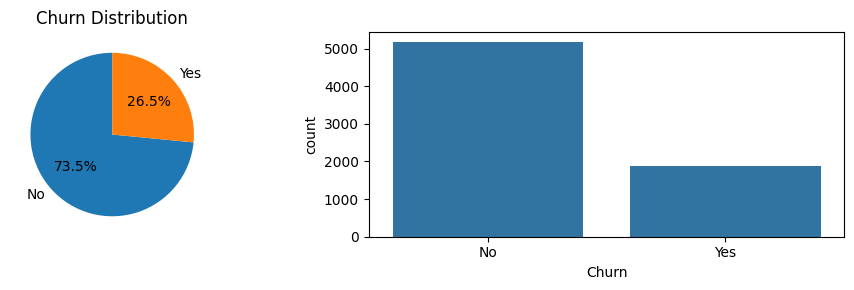

In [7]:
churn_counts = df['Churn'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].pie(churn_counts, 
            labels=churn_counts.index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0].set_title('Churn Distribution')

sns.countplot(data=df, x='Churn', ax=axes[1])
fig.tight_layout()
plt.show()

__Separate Feature and target columns from the dataset__

In [8]:
features = df.drop(columns=['Churn', 'index', 'customerID'])
target = df['Churn']

__Gender:__ Whether the customer is a male or a female

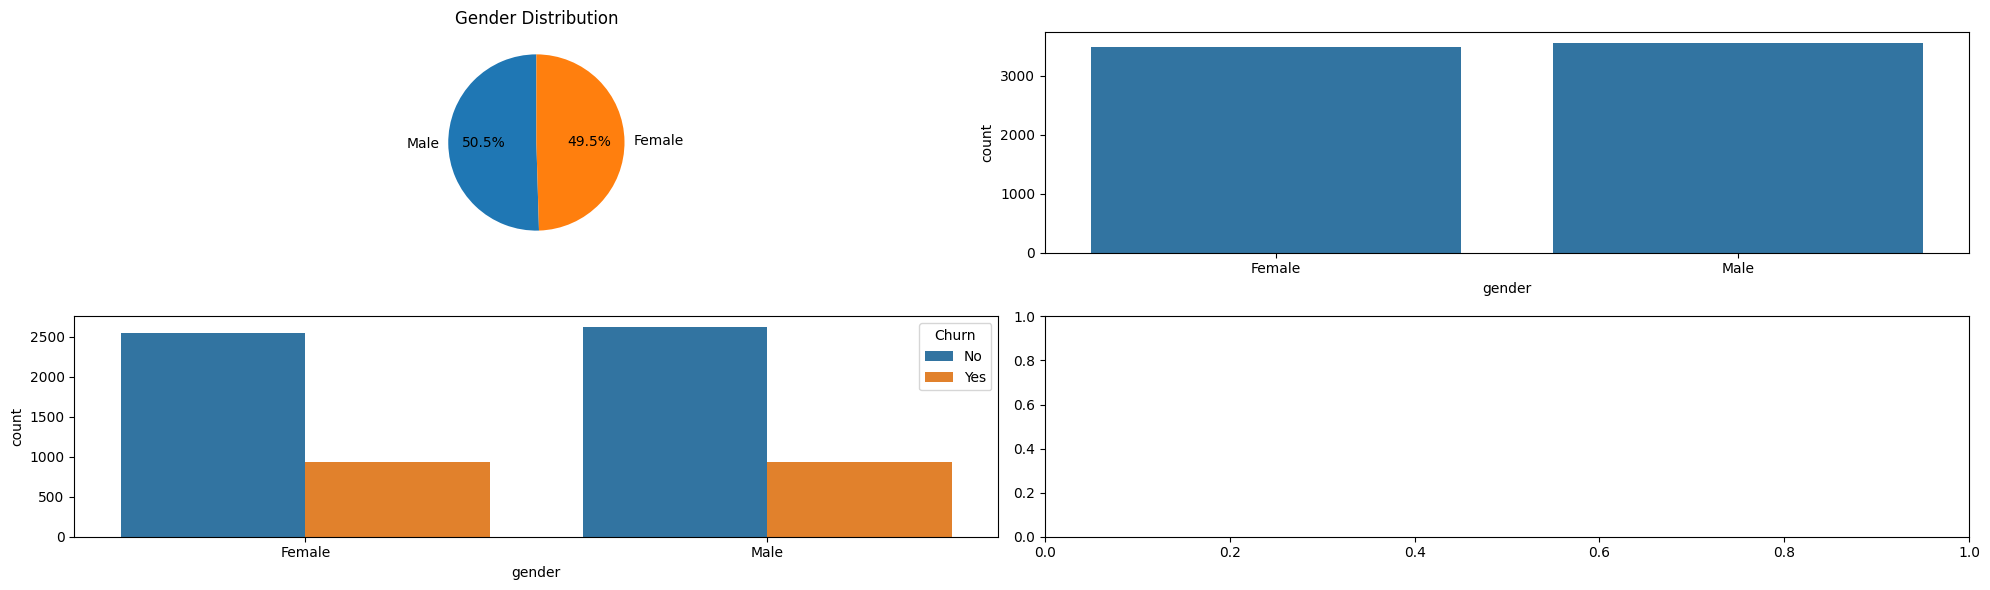

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['gender'].value_counts(), 
            labels=features['gender'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Gender Distribution')

sns.countplot(data=features, x='gender', ax=axes[0, 1])
sns.countplot(data=features, x='gender', hue=target, ax=axes[1, 0])

fig.tight_layout()

plt.show()

__We have 50.5% of male and 49.5% of female here and in counts there are 3555 male and 3488 female customers.__

In [10]:
print(features['SeniorCitizen'].value_counts())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In `SeniorCitizen` columns we have only value 0 and 1. That means `boolean` value is that this __individual__ is __SeniorCitizen__ or not.

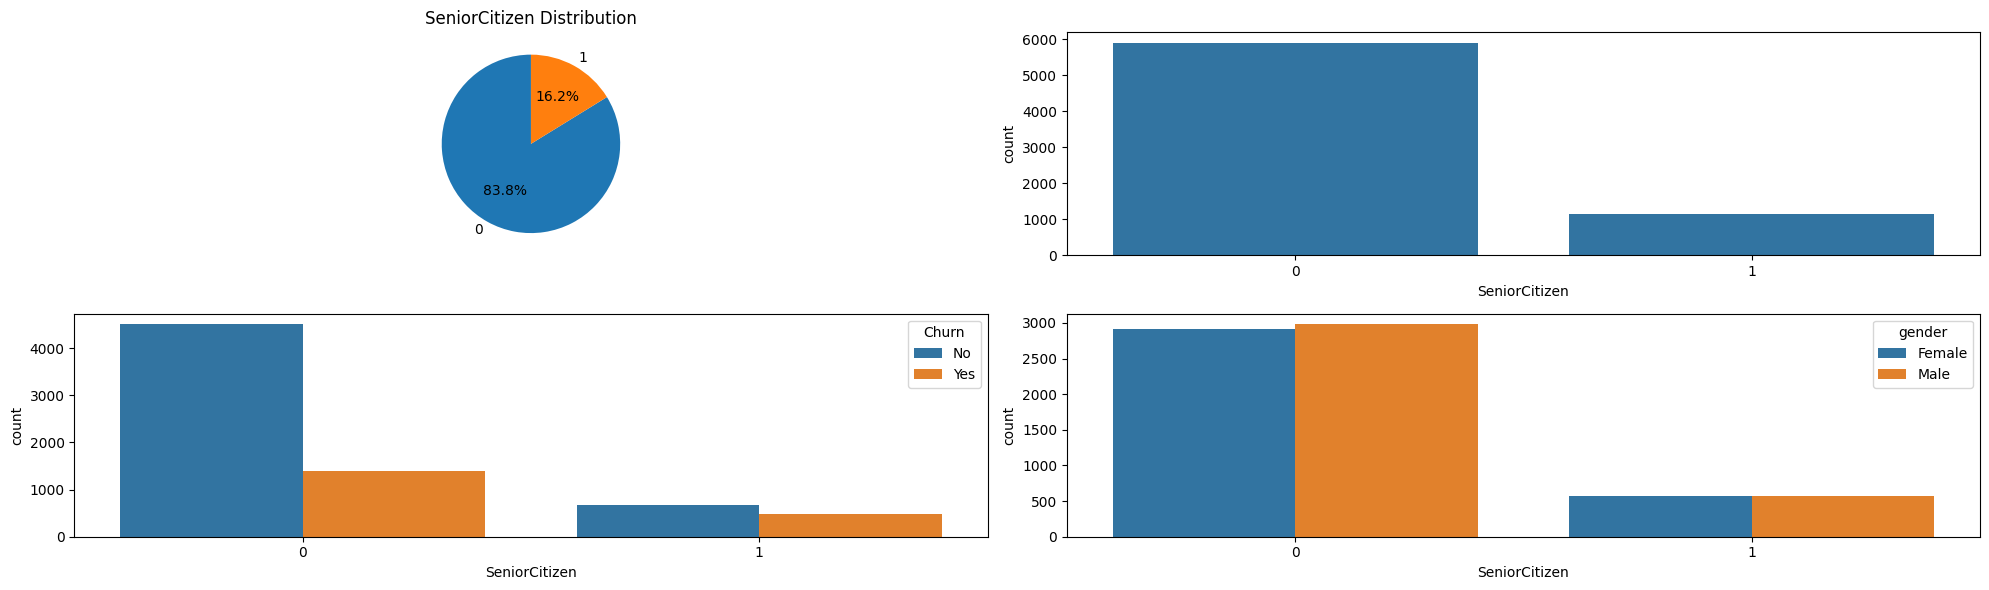

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['SeniorCitizen'].value_counts(), 
            labels=features['SeniorCitizen'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('SeniorCitizen Distribution')

sns.countplot(data=features, x='SeniorCitizen', ax=axes[0, 1])
sns.countplot(data=features, x='SeniorCitizen', hue=target, ax=axes[1, 0])
sns.countplot(data=features, x='SeniorCitizen', hue='gender', ax=axes[1, 1])


fig.tight_layout()

plt.show()

In [12]:
features['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

__Partner:__ Whether the customer has a partner or not (Yes, No)

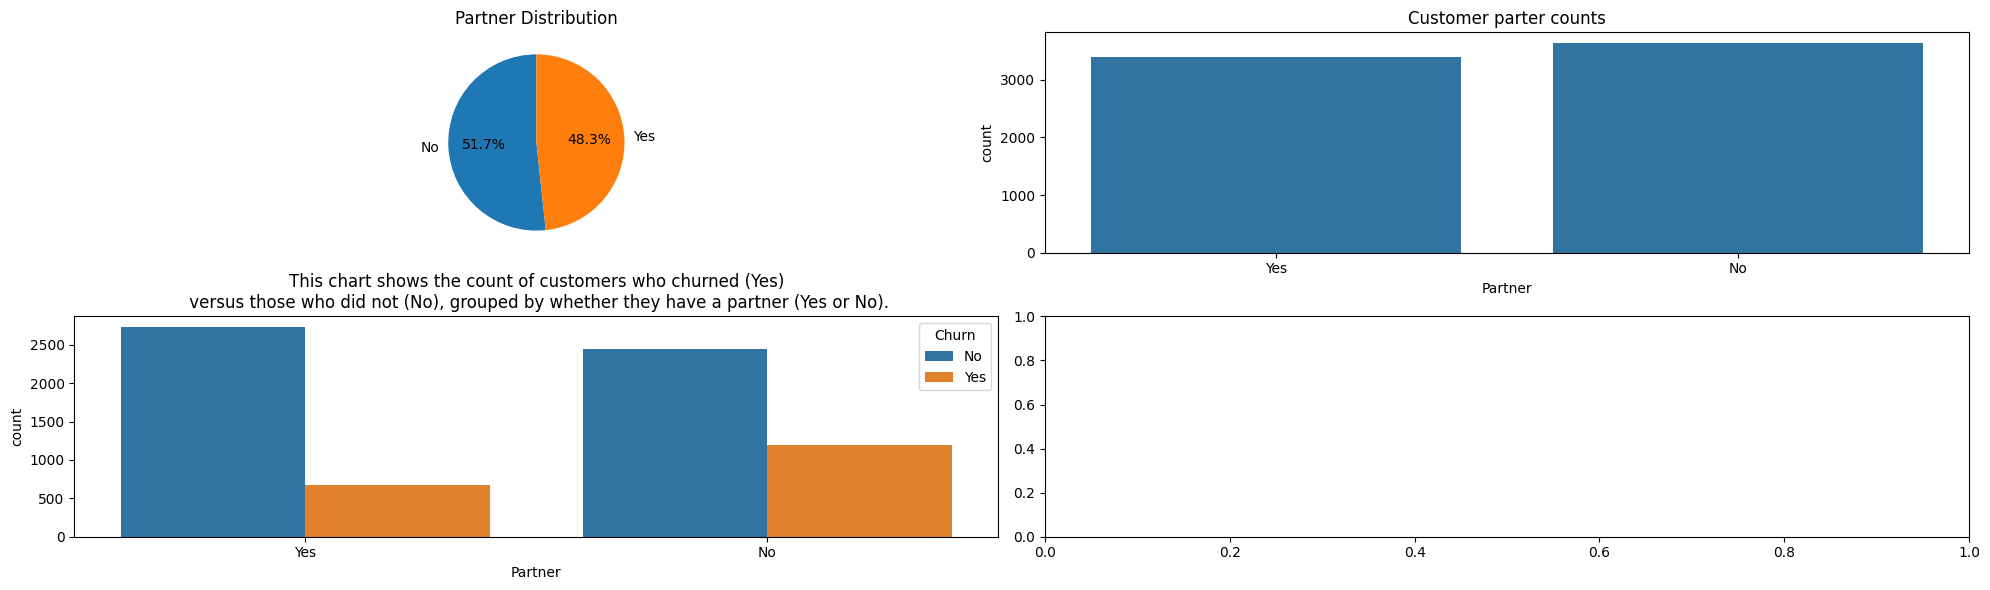

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Partner'].value_counts(), 
            labels=features['Partner'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Partner Distribution')

sns.countplot(data=features, x='Partner', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Partner', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of customers who churned (Yes)\n versus those who did not (No), grouped by whether they have a partner (Yes or No).')
fig.tight_layout()

plt.show()

In dataset there are 48.3% of individual who have __parterns__ and 51.7% who dont have __Parterns__

Customers with a __Partner__ (Yes on the left): Roughly 2,700 stayed (Churn = No), while around 650 churned (Churn = Yes) - a relatively low churn rate.
Customers without a __Partner__ (No on the right): Roughly 2,400 stayed (Churn = No), while about 1,200 churned (Churn = Yes) — nearly double the number of churns compared to customers with partners.

<br><br>
__Dependents:__ Whether the customer has dependents or not (Yes, No)

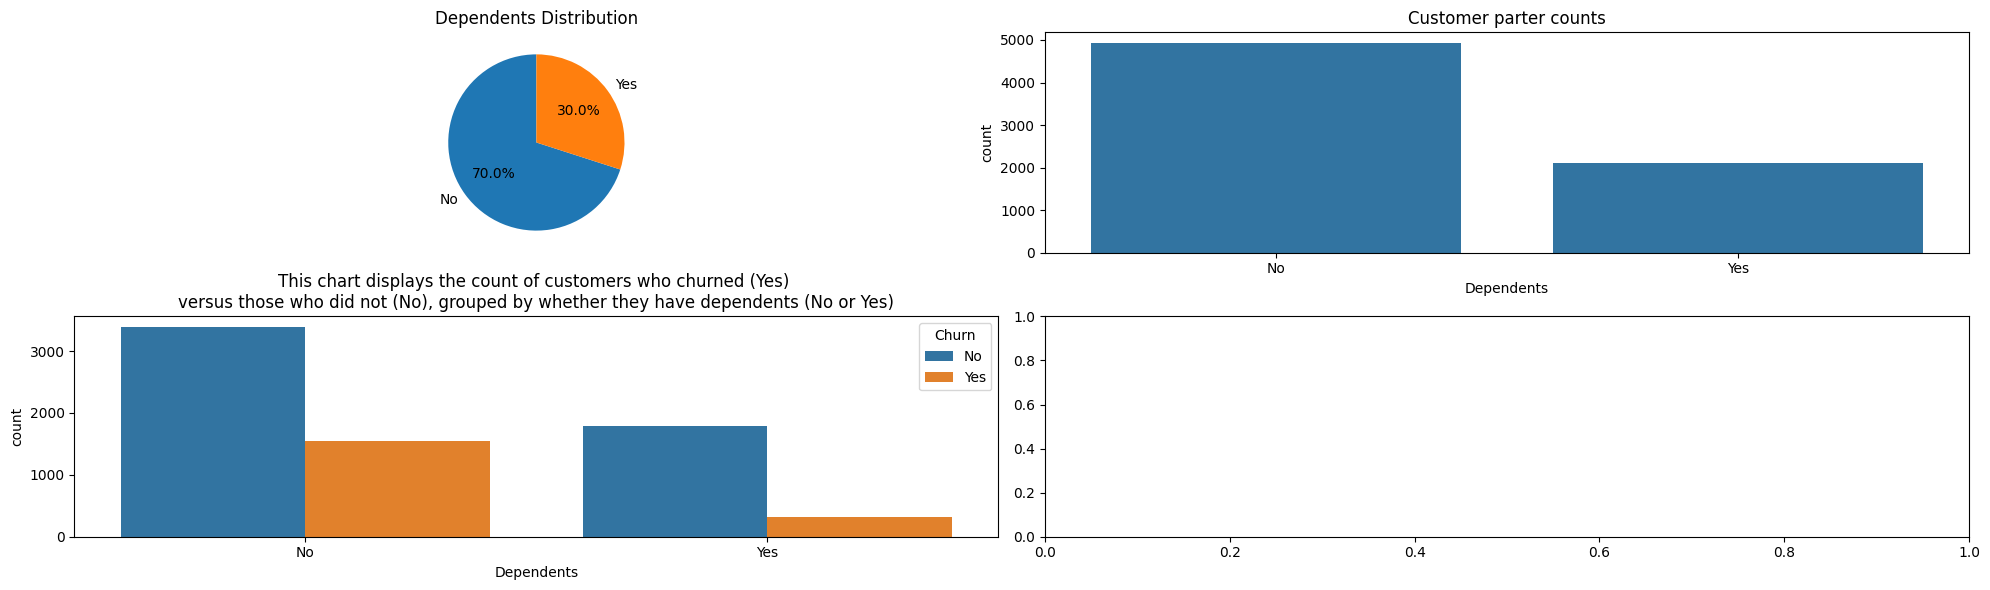

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Dependents'].value_counts(), 
            labels=features['Dependents'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Dependents Distribution')

sns.countplot(data=features, x='Dependents', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Dependents', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have dependents (No or Yes)')

fig.tight_layout()
plt.show()

In dataset there are 30% of individual who have __Dependents__ and 70% of individual who dont have any __Dependents__

1. Customers without __Dependents__ (No on the left): This is the largest group overall. Roughly 3,400 customers stayed (Churn = No), while over 1,500 churned (Churn = Yes), representing a high churn count and rate.
2. Customers with __Dependents__ (Yes on the right): Fewer customers in the dataset have dependents. Around 1,800 stayed (Churn = No), while only about 300 churned (Churn = Yes), showing a significantly lower churn rate compared to those without dependents.

<br><br>
__Tenure:__ Number of months the customer has stayed with the company

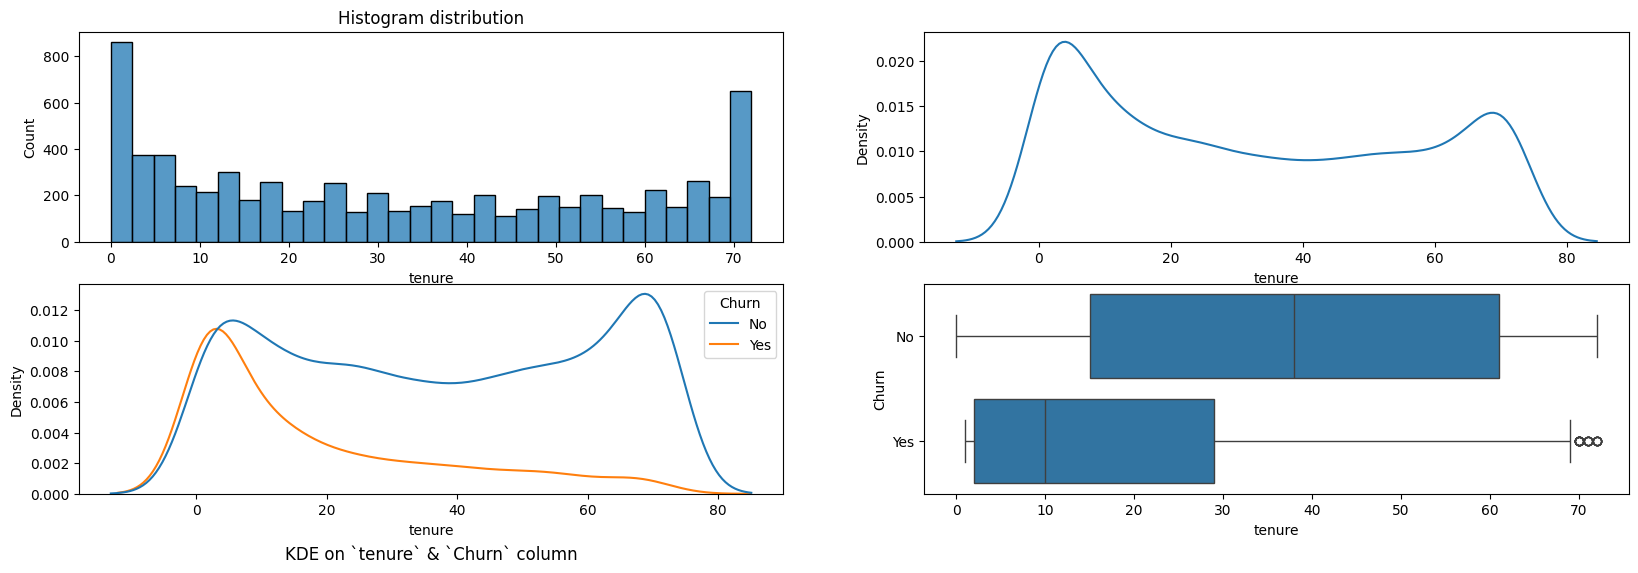

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

sns.histplot(data=features, x='tenure', bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', ax=axes[0, 1])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('KDE on `tenure` & `Churn` column', y=-0.35)

sns.boxplot(data=features, x='tenure', y=target, ax=axes[1, 1])

plt.show()

Histogram displays the row count of customers across different tenure lengths. It highlights a bimodal(2 peak) pattern:
1. __New customers:__ There is a massive spike at the very begining 0-3 months, meaning the company accquires a high volume of new customers.
2. __Loyal customers:__ There is a second major peak near the 70-month mark, showing that a large group of customers stays with the company for a very long time

<br>

__KDE with `tenure` and `Churn` column__
* __High churn at lower tenure(New customers):__ The orange line (churn = yes) has a steep peak at the very begining (between 0 and 10 months). This indicates that new customers are much more likely to churn early on.

* __Lower Tenure equal higher retension:__ The blue line (Churn = No) stays prominent across all tenures and shows a major peak around 70 months. This means customers who stick around for a long time are significantly less likely to churn

__PhoneService:__ Whether the customer has a phone service or not (Yes, No)

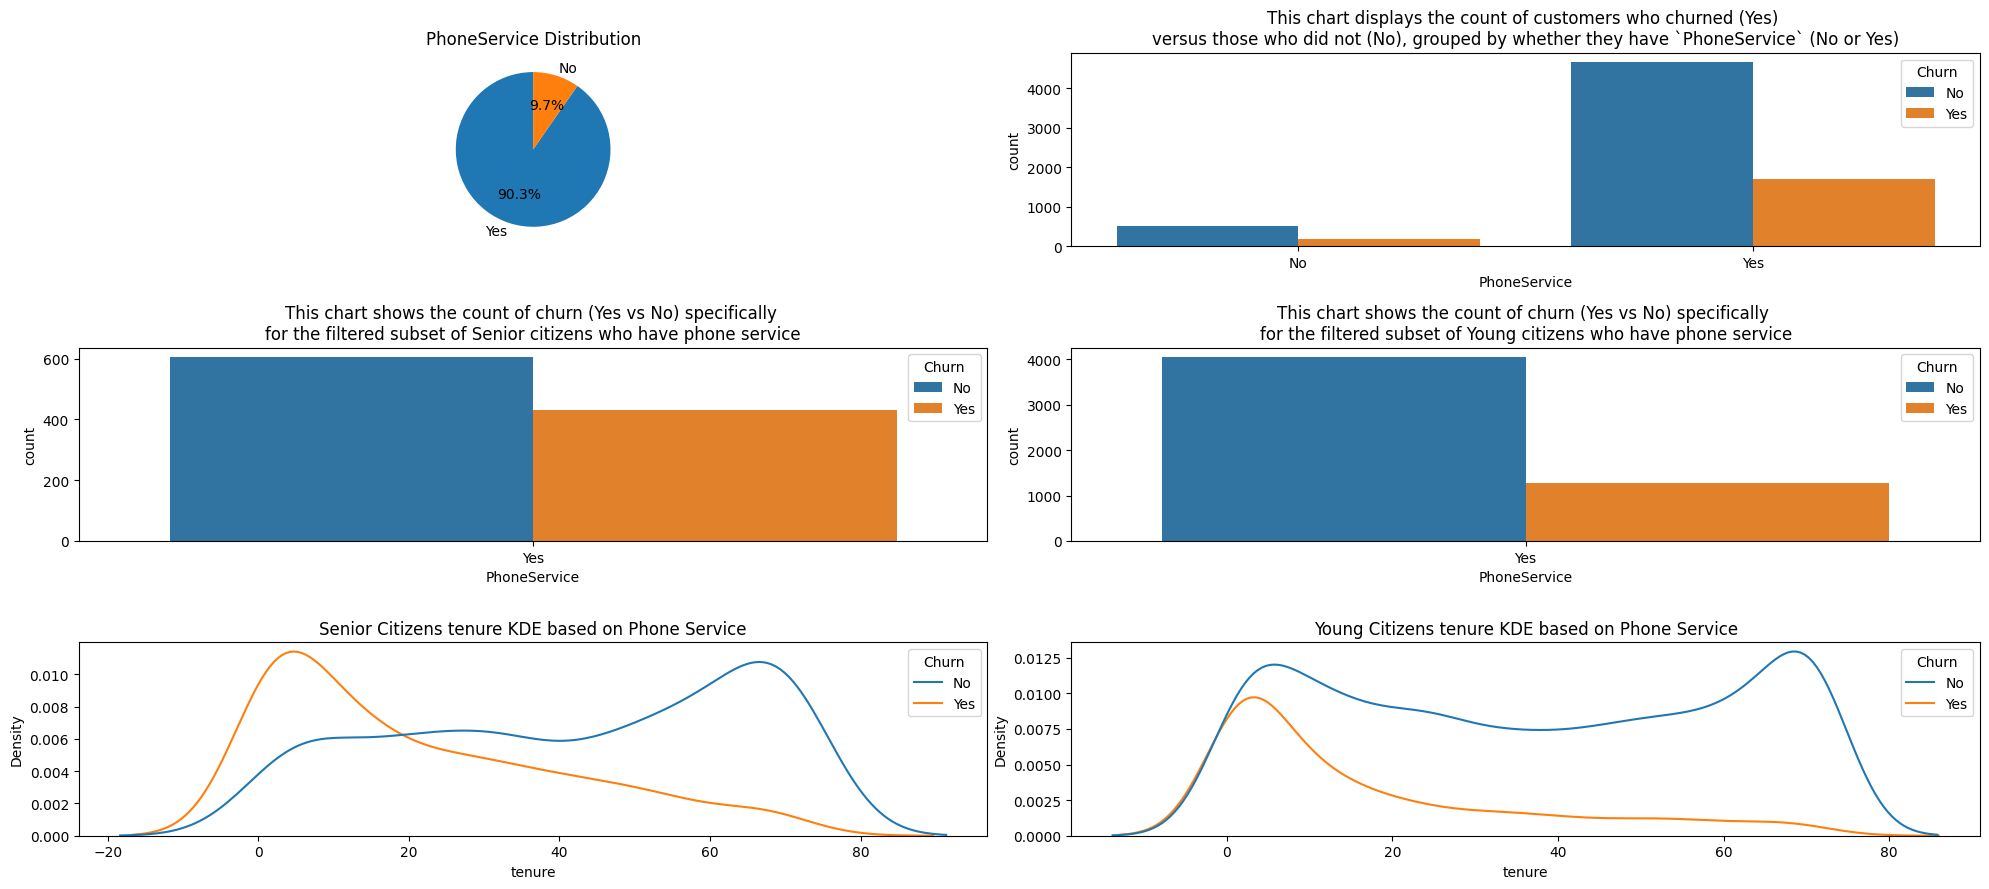

In [ ]:
senior_citizen_who_get_phone_service_df = features[(features['PhoneService'] == 'Yes') & (features['SeniorCitizen'] == 1)]
young_citizen_who_get_phone_service_df = features[(features['PhoneService'] == 'Yes') & (features['SeniorCitizen'] == 0)]

fig, axes = plt.subplots(3, 2, figsize=(20, 9))

axes[0, 0].pie(features['PhoneService'].value_counts(), 
            labels=features['PhoneService'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('PhoneService Distribution')

# sns.countplot(data=features, x='PhoneService', ax=axes[0, 1])
# axes[0, 1].set_title('Customer PhoneService counts')

sns.countplot(data=features, x='PhoneService', hue=target, ax=axes[0, 1])
axes[0, 1].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have `PhoneService` (No or Yes)')

sns.countplot(data=senior_citizen_who_get_phone_service_df, x='PhoneService', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Senior citizens who have phone service')

sns.countplot(data=young_citizen_who_get_phone_service_df, x='PhoneService', hue=target, ax=axes[1, 1])
axes[1, 1].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Young citizens who have phone service')

sns.kdeplot(data=senior_citizen_who_get_phone_service_df, x='tenure', hue=target, ax=axes[2, 0])
axes[2, 0].set_title('Senior Citizens tenure KDE based on Phone Service')

sns.kdeplot(data=young_citizen_who_get_phone_service_df, x='tenure', hue=target, ax=axes[2, 1])
axes[2, 1].set_title('Young Citizens tenure KDE based on Phone Service')

fig.tight_layout()
plt.show()

* __Customers with Phone Service (Yes):__ This represents the overwhelming majority of the customer base. Roughly 4600 customer stayed (Churn = No), While about 1700 churned or (Churn = Yes)

* __Customers with Phone Service (No):__ This is very small portion of the data. Around 500 customers stayed (Churn = No) while roughly 200 individual churned (Churn = Yes)

__MultipleLines:__ Whether the customer has multiple lines or not (Yes, No, No phone service)

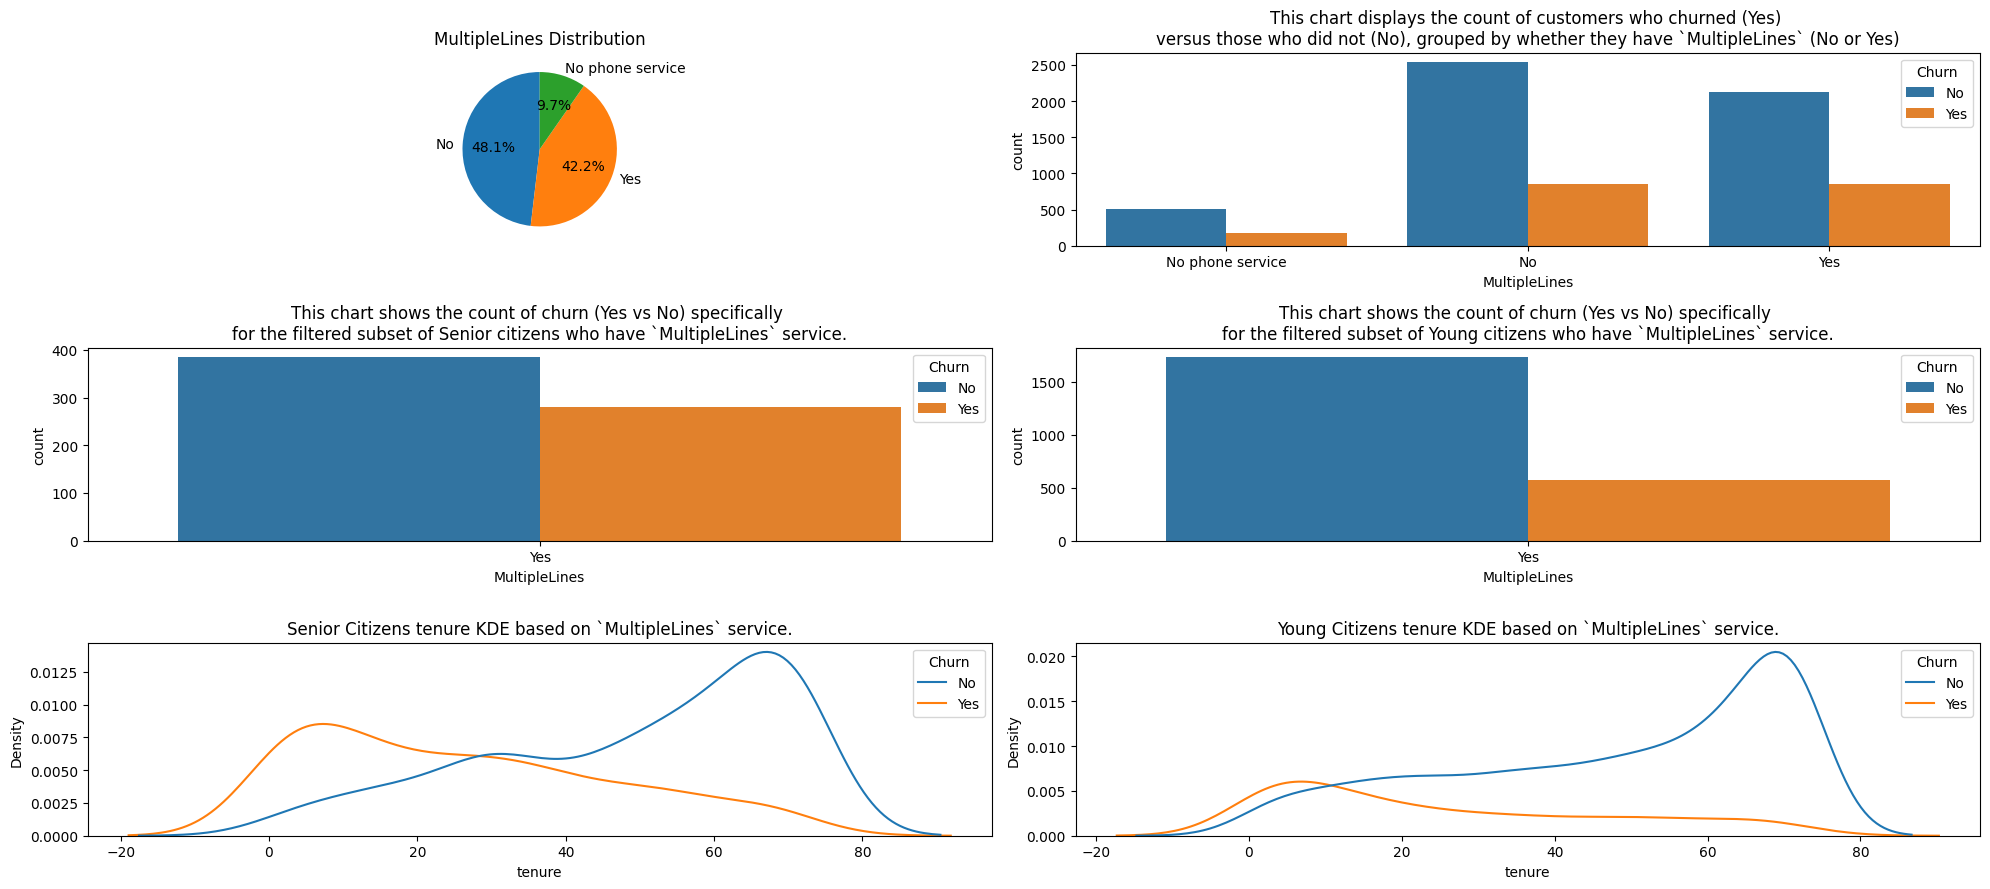

In [54]:
senior_citizen_who_get_multiple_lines_df = features[(features['MultipleLines'] == 'Yes') & (features['SeniorCitizen'] == 1)]
young_citizen_who_get_multiple_lines_df = features[(features['MultipleLines'] == 'Yes') & (features['SeniorCitizen'] == 0)]

fig, axes = plt.subplots(3, 2, figsize=(20, 9))

axes[0, 0].pie(features['MultipleLines'].value_counts(), 
            labels=features['MultipleLines'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('MultipleLines Distribution')

sns.countplot(data=features, x='MultipleLines', hue=target, ax=axes[0, 1])
axes[0, 1].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have `MultipleLines` (No or Yes)')

sns.countplot(data=senior_citizen_who_get_multiple_lines_df, x='MultipleLines', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Senior citizens who have `MultipleLines` service.')

sns.countplot(data=young_citizen_who_get_multiple_lines_df, x='MultipleLines', hue=target, ax=axes[1, 1])
axes[1, 1].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Young citizens who have `MultipleLines` service.')

sns.kdeplot(data=senior_citizen_who_get_multiple_lines_df, x='tenure', hue=target, ax=axes[2, 0])
axes[2, 0].set_title('Senior Citizens tenure KDE based on `MultipleLines` service.')

sns.kdeplot(data=young_citizen_who_get_multiple_lines_df, x='tenure', hue=target, ax=axes[2, 1])
axes[2, 1].set_title('Young Citizens tenure KDE based on `MultipleLines` service.')

fig.tight_layout()
plt.show()

* __No phone service:__ A small group of about 500 customer stayed Churn = No, while roughly 200 individuals are churned.
* __No Multiple Lines:__ This is the largest segment, around 2500 plus customers stayed Churn = No, while about 800 plus are churned (Churn = Yes)
* __Yes Multiple Lines:__ Roughly 2100 plus customers stayed churn = no and about 800 plus individuals are churned. The actual number pf customers who churned is identical to the "No" group, though the retention count is slightly low.

In KDE plot there is a clear peak at a low tenure (5~10) months indicating that individual(Senior/Young) who decide to leave(Churn = Yes) tend to do so early in their customer lifecycle and the blue line features a sharp dominant peak near (65~70) months, showing that senior citizens who stick with the company fo a long time are far less likely to churn

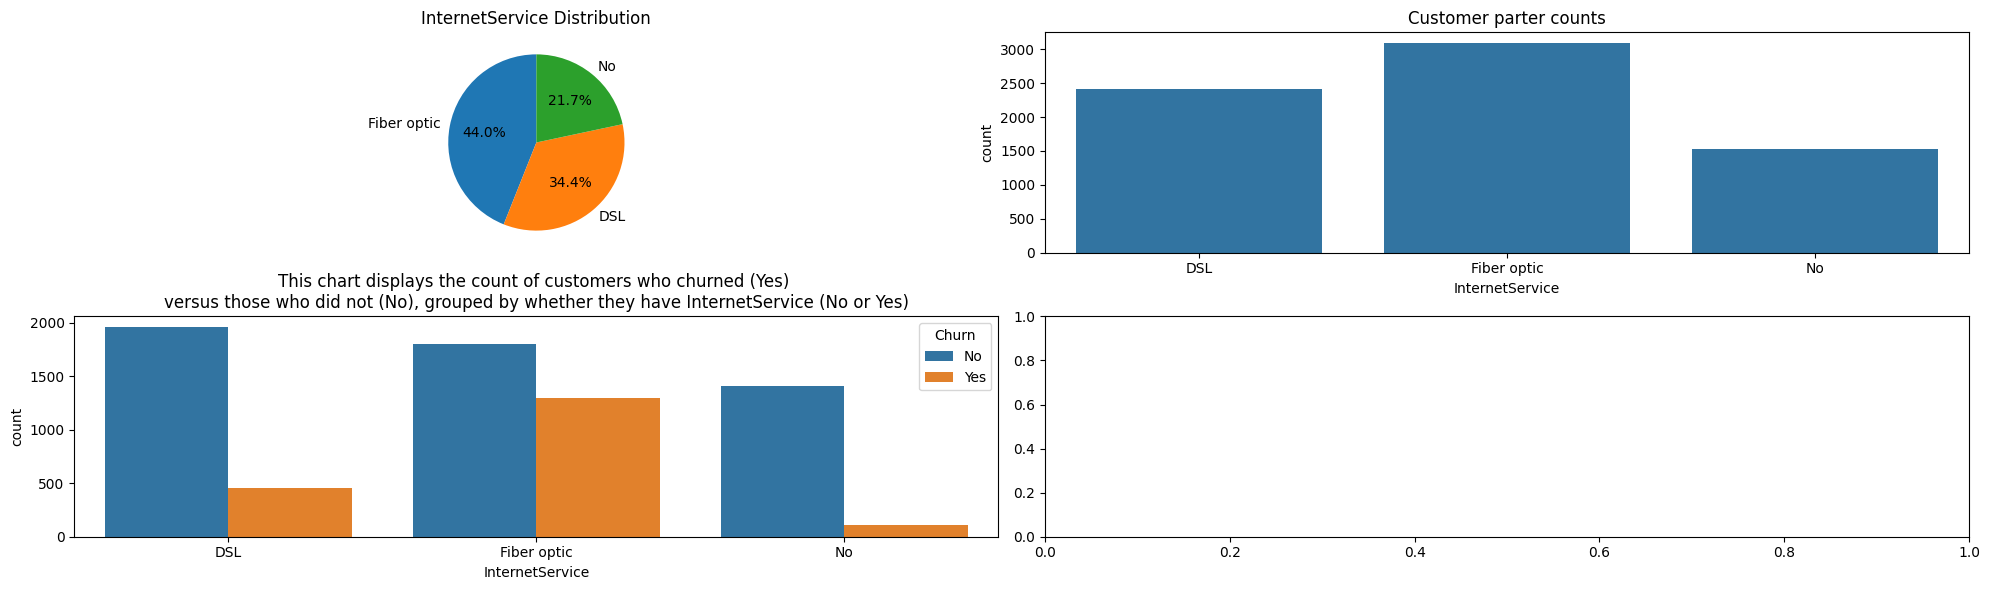

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['InternetService'].value_counts(), 
            labels=features['InternetService'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('InternetService Distribution')

sns.countplot(data=features, x='InternetService', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='InternetService', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have InternetService (No or Yes)')

fig.tight_layout()
plt.show()

In [ ]:
features.columns

# features['PhoneService']
# features['MultipleLines']
# features['InternetService']
# features['OnlineSecurity']
# features['OnlineBackup']
# features['DeviceProtection']
# features['TechSupport']
# features['StreamingTV']
# features['StreamingMovies']

# features['Contract'].value_counts()
# features['PaperlessBilling'].value_counts()

# features['PaymentMethod'].value_counts()

# features['MonthlyCharges']

# features['TotalCharges']

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, Length: 7043, dtype: object